<a href="https://colab.research.google.com/github/muiddd/5thSemester_PCVK/blob/main/Week07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

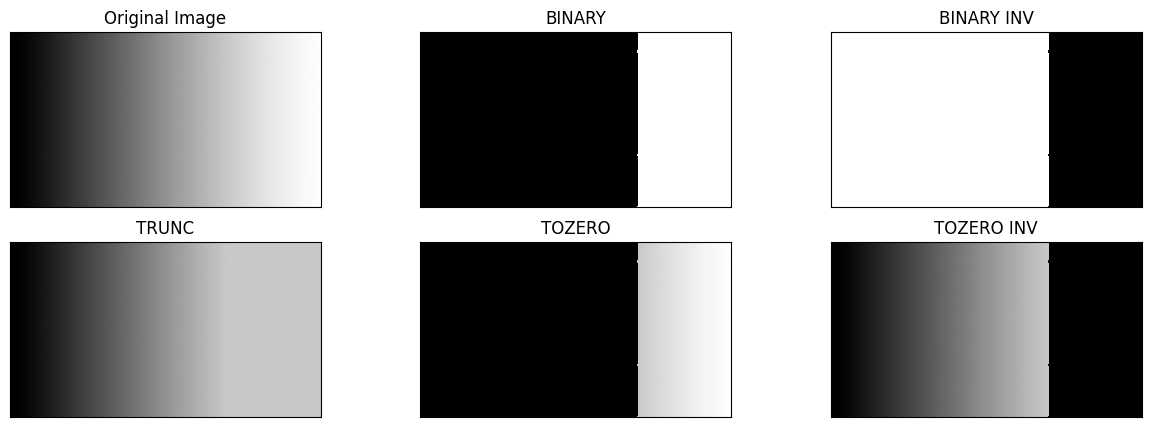

In [4]:
filename = ('/content/drive/MyDrive/PCVK/Images/gradient.jpg')
img = cv.imread(filename)
thresh = 200       #nilai Threshold yang ditentukan
maxval = 255

#1. threshold binary jika pixel di img>127, maka thresh1 bernilai 1 (putih) selain itu bernilai 0 (hitam)
ret, thresh1 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY)

#2. threshold binary inverse jika pixel>thresh, maka pixel bernilai 0; selain itu akan bernilai maxval
ret, thresh2 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY_INV)

#3. Threshold Truncate jika pixel>thresh, maka pixel bernilai thresh; selain itu akan bernilai tetap
ret, thresh3 = cv.threshold(img, thresh, maxval, cv.THRESH_TRUNC)

#4. Threshold Tozero jika pixel>thresh, maka pixel bernilai tetap; selain itu akan bernilai 0
ret, thresh4 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO)

#5. Threshold Tozero Inverse jika pixel>thresh, maka pixel bernilai 0; selain itu akan bernilai tetap
ret, thresh5 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO_INV)

titles = ['Original Image', 'BINARY', 'BINARY INV', 'TRUNC', 'TOZERO', 'TOZERO INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15,5))
for i in range(len(images)):
    plt.subplot(2,3,i+1), plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

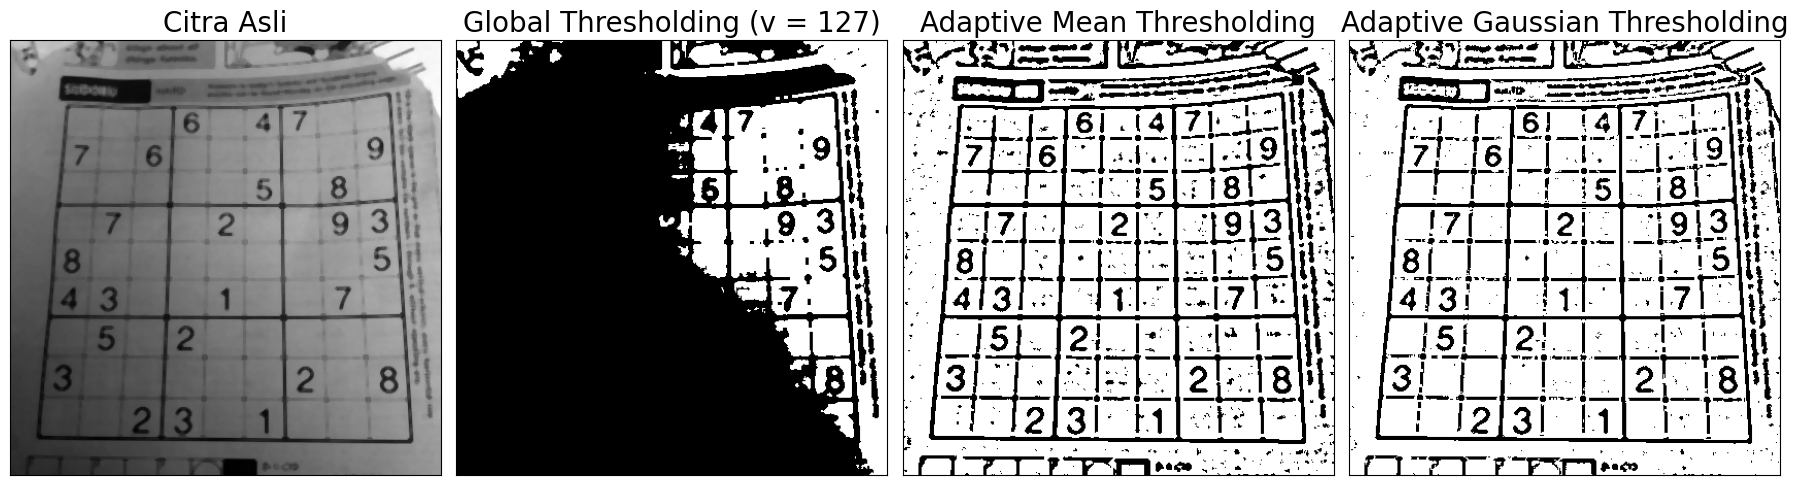

In [17]:
filename = ('/content/drive/MyDrive/PCVK/Images/sudoku-original.jpg')
citra = cv.medianBlur(cv.imread(filename),5)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

thresh = 127

ret,th1 = cv.threshold(gray,thresh,255,cv.THRESH_BINARY)
th2 = cv.adaptiveThreshold(gray,255,cv.ADAPTIVE_THRESH_MEAN_C,
cv.THRESH_BINARY,11,2)
th3 = cv.adaptiveThreshold(gray,255,cv.ADAPTIVE_THRESH_GAUSSIAN_C,
cv.THRESH_BINARY,11,2)

titles = ['Citra Asli', 'Global Thresholding (v = 127)',
'Adaptive Mean Thresholding', 'Adaptive Gaussian Thresholding']
citra2 = [gray, th1, th2, th3
          ]
plt.figure(figsize = (18, 5))
for i in range(len(citra2)):
  plt.subplot(1, 4, i+1),plt.imshow(citra2[i],'gray')
  plt.title(titles[i], fontsize=20)
  plt.xticks([]),plt.yticks([])
plt.tight_layout()
plt.show()

/tmp/ipykernel_622/2723289004.py:18: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_622/2723289004.py:19: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


93


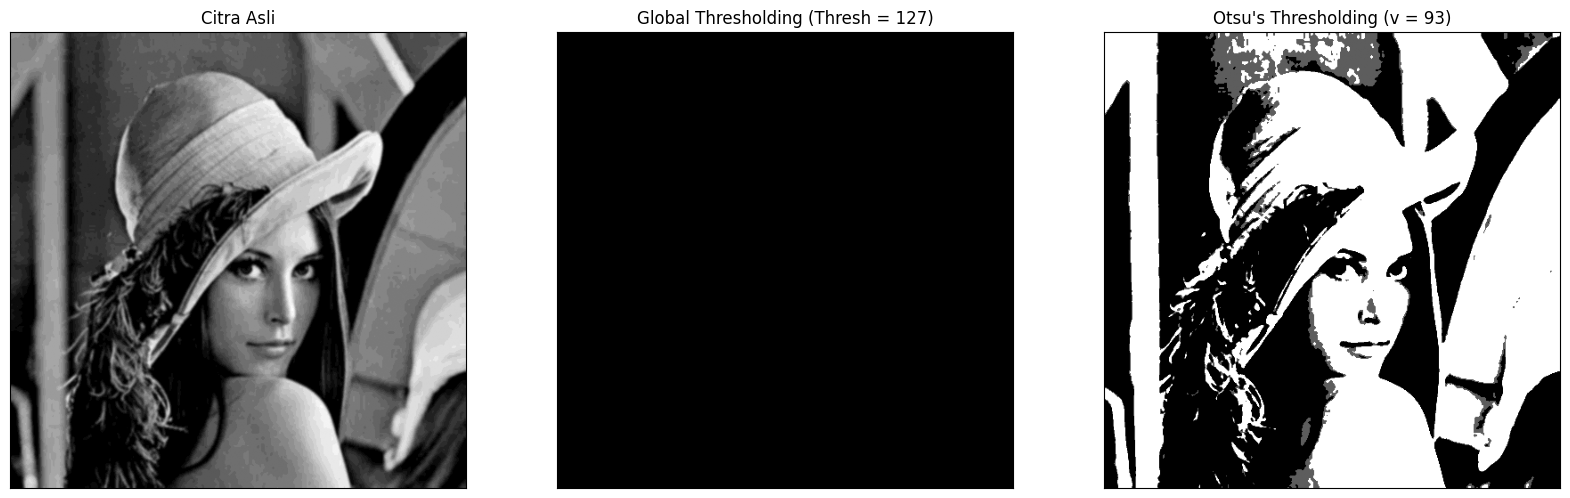

In [18]:
filename = ('/content/drive/MyDrive/PCVK/Images/lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) +
')', x]
citra3 = [blur, th1, otsu_biner]
plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

/tmp/ipykernel_622/1735501263.py:3: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(), 256, [0, 256], color='gray')


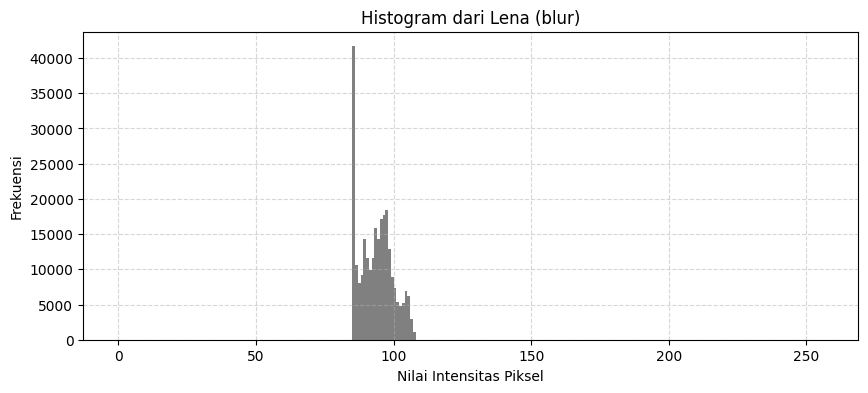

Nilai piksel minimum: 85
Nilai piksel maksimum: 108


In [19]:
# 1. Menampilkan histogram dari gambar Lena (blur)
plt.figure(figsize=(10, 4))
plt.hist(blur.ravel(), 256, [0, 256], color='gray')
plt.title('Histogram dari Lena (blur)')
plt.xlabel('Nilai Intensitas Piksel')
plt.ylabel('Frekuensi')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 2. Menghitung nilai minimum dan maksimum piksel
min_val = blur.min()
max_val = blur.max()
print(f"Nilai piksel minimum: {min_val}")
print(f"Nilai piksel maksimum: {max_val}")

/tmp/ipykernel_622/2150658184.py:18: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)


166


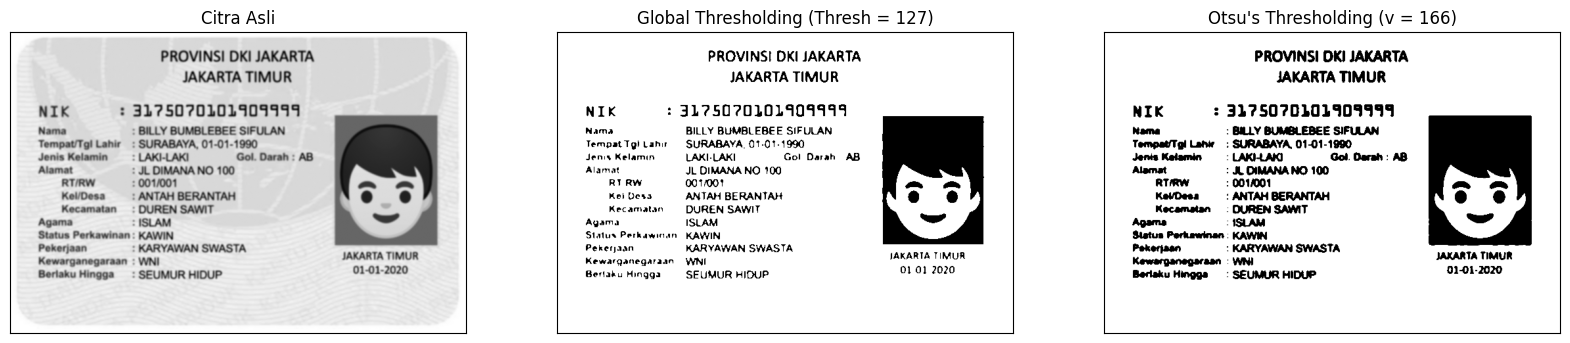

In [20]:
filename = ('/content/drive/MyDrive/PCVK/Images/ktp1.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) +
')', x]
citra3 = [blur, th1, otsu_biner]
plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

Perbedaan yang sangat kontras ini terjadi karena karakteristik distribusi pencahayaan (kontras) pada kedua gambar tersebut:

**Gambar Lena (lena_gs_lc2.jpg):**

Tipe Kontras Rendah (Low Contrast & Dark): Gambar Lena ini sengaja dibuat sangat redup/gelap. Seluruh informasi gambar bertumpuk di rentang piksel yang sangat sempit dan gelap (85 - 108).
Efek Threshold 127: Karena ambang batas global 127 jauh lebih tinggi dibanding seluruh piksel gambar, gambar menjadi hitam total.
Hasil Otsu: Metode Otsu berhasil mendeteksi puncak pemisah pada nilai 93, sehingga gambarnya masih dapat terlihat dengan baik.

**Gambar KTP Fulan (ktp1.jpg):**

Tipe Kontras Tinggi/Terang: Gambar KTP umumnya memiliki latar belakang putih terang (mendekati 255) dengan teks tulisan berwarna hitam gelap (mendekati 0). Ini menghasilkan histogram bimodal yang sangat jelas dengan sebaran piksel yang luas (dari 0 hingga 255).
Efek Threshold 127: Ambang batas global 127 bekerja sangat baik pada jenis gambar dokumen seperti ini karena memotong tepat di antara teks gelap dan kertas putih terang. Oleh karena itu, tulisan KTP masih terbaca jelas.
Hasil Otsu: Otsu mendeteksi nilai ambang batas optimal yang lebih tinggi yaitu 166 karena menyesuaikan dengan dominasi warna putih latar belakang KTP agar teks hitam tetap terisolasi dengan sempurna tanpa banyak noise.


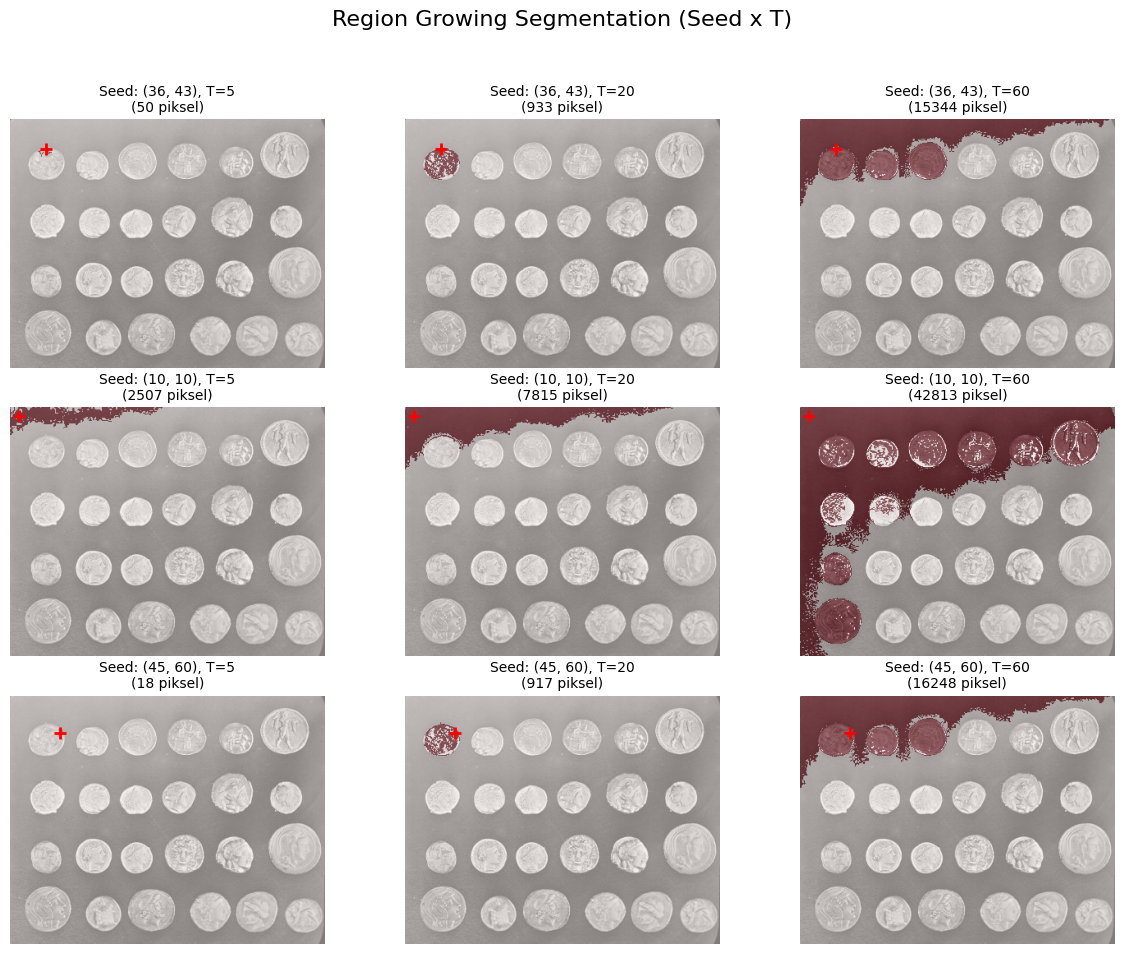

In [24]:
# Fungsi Region Growing
def region_growing(img, seed, T):
    rows, cols = img.shape
    segmented = np.zeros_like(img, dtype=bool)
    segmented[seed] = True

    # 8-ketetanggaan
    neighbors = [(-1, -1), (-1, 0), (-1, 1),
                 (0, -1),           (0, 1),
                 (1, -1), (1, 0), (1, 1)]

    seed_value = float(img[seed])
    pixel_list = [seed]

    while len(pixel_list) > 0:
        cx, cy = pixel_list.pop(0)

        for dx, dy in neighbors:
            nx, ny = cx + dx, cy + dy

            # Cek batas citra dan piksel belum disegmentasi
            if 0 <= nx < rows and 0 <= ny < cols and not segmented[nx, ny]:
                # Cek kriteria toleransi (T)
                if abs(float(img[nx, ny]) - seed_value) <= T:
                    segmented[nx, ny] = True
                    pixel_list.append((nx, ny))

    return segmented

# 1. Load citra
img = data.coins()

# 2. Tentukan 3 titik seed:
# Koordinat (baris, kolom). Sesuaikan dengan posisi yang Anda inginkan
seeds = [
    (36, 43),   # Seed di dalam koin
    (10, 10),   # Seed di latar belakang
    (45, 60)    # Seed di tepi koin (antara koin & latar)
]

# 3. Tentukan 3 nilai toleransi (T)
T_values = [5, 20, 60]

# 4. Siapkan subplot grid 3x3
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
fig.suptitle('Region Growing Segmentation (Seed x T)', fontsize=16)

# Looping untuk baris (berdasarkan seed)
for i, seed in enumerate(seeds):
    # Looping untuk kolom (berdasarkan nilai T)
    for j, T in enumerate(T_values):
        # Proses region growing
        segmented_mask = region_growing(img, seed, T)

        # Plot gambar
        ax = axes[i, j]
        ax.imshow(img, cmap='gray')

        # Overlay hasil segmentasi warna merah transparan
        ax.imshow(segmented_mask, cmap='Reds', alpha=0.5)

        # Tambahkan tanda titik (+) merah untuk posisi seed
        ax.plot(seed[1], seed[0], 'r+', markersize=8, markeredgewidth=2)

        # Setel judul tiap subplot
        pixel_count = np.sum(segmented_mask)
        ax.set_title(f"Seed: {seed}, T={T}\n({pixel_count} piksel)", fontsize=10)
        ax.axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()